# Use viewmastR with saved models

`viewmastR()` saves every model it trains. `viewmastR_infer()` labels new data with a
saved model, so one reference model can label many queries. This tutorial follows the R
article [How to use viewmastR with saved models](https://furlan-lab.github.io/viewmastR/articles/SavedModel.html).

| Role | Dataset |
|---|---|
| Reference | healthy bone marrow atlas (Granja et al. 2019, "Greenleaf reference") |
| Query | CD34+ enriched bone marrow, multiome RNA (Persad et al. 2023, Zenodo 6383269) |

A model directory holds `model.mpk` (the burn weights) and `meta.mpk` (features and
class names), the same files R viewmastR writes, so Python can also label data with
models trained in R.

In [1]:
import tempfile
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
import viewmastr as vm
import tutorial_data as td

sc.set_figure_params(dpi=80, frameon=False)
label = td.config().get("greenleaf_label", "celltype")
ref = td.greenleaf_reference()
query = td.multiome_rna("cd34")
for a in (query, ref):
    vm.calculate_feature_dispersion(a)
    vm.select_features(a, top_n=10_000, logmean_ul=-1, logmean_ll=-8)
vgr = set(vm.get_selected_features(ref))
vg = [g for g in vm.get_selected_features(query) if g in vgr]

## Train and save

`model_dir` sets where the model goes.

viewmastR: 5955 features, 16 classes, 29054 train / 7264 test cells


[epoch 1 | train accuracy 85.950% | validation accuracy 94.383%]


[epoch 2 | train accuracy 96.407% | validation accuracy 94.948%]


[epoch 3 | train accuracy 97.635% | validation accuracy 95.333%]


['meta.mpk', 'model.mpk', 'viewmastr.json']


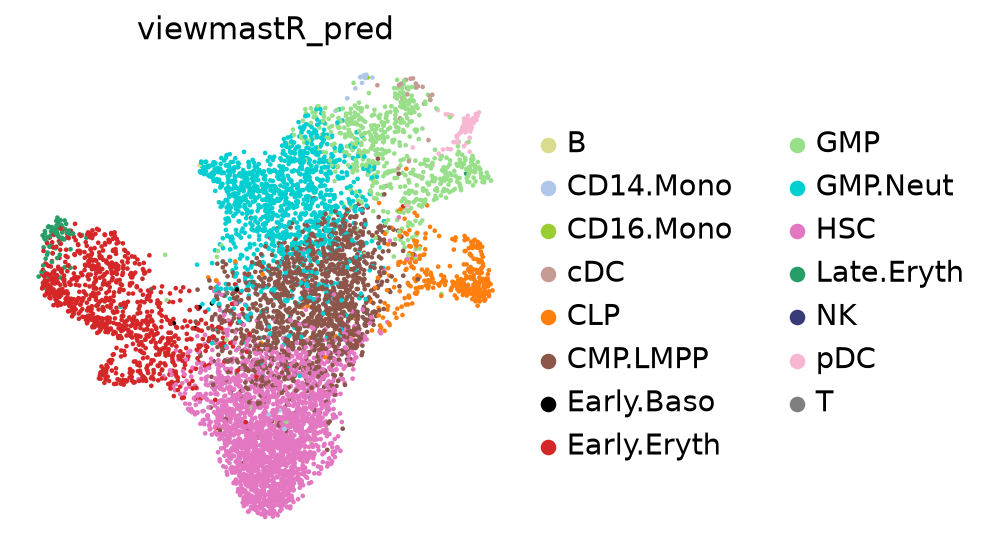

In [2]:
model_dir = Path(tempfile.mkdtemp()) / "greenleaf_model"
vm.viewmastR(query, ref, label, selected_features=vg, model_dir=model_dir, max_epochs=3, return_probs=True)
print(sorted(p.name for p in model_dir.iterdir()))
vm.palette.set_colors(query, "viewmastR_pred")
sc.pl.umap(query, color="viewmastR_pred")

## Infer from the saved model

Pass the same features the model was trained on. `query_celldata_col` names the output
column (default `viewmastR_inferred`).

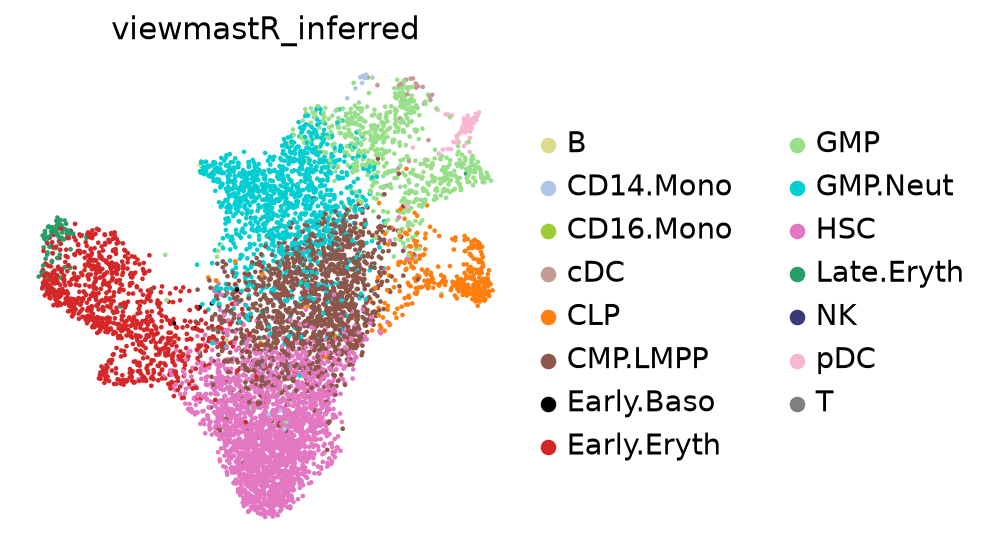

In [3]:
inferred = vm.viewmastR_infer(query.copy(), model_dir, vg, return_probs=True)
vm.palette.set_colors(inferred, "viewmastR_inferred")
sc.pl.umap(inferred, color="viewmastR_inferred")

## Compare training-time and saved-model labels

py-viewmastR normalises the query in exactly the same way in both paths, so the labels
agree on every cell and the probabilities agree to float precision. (R viewmastR 0.5.0
normalises differently at inference; see "Differences from the R package" in the README.)

label agreement: 1.0000
largest probability difference: 0.00e+00


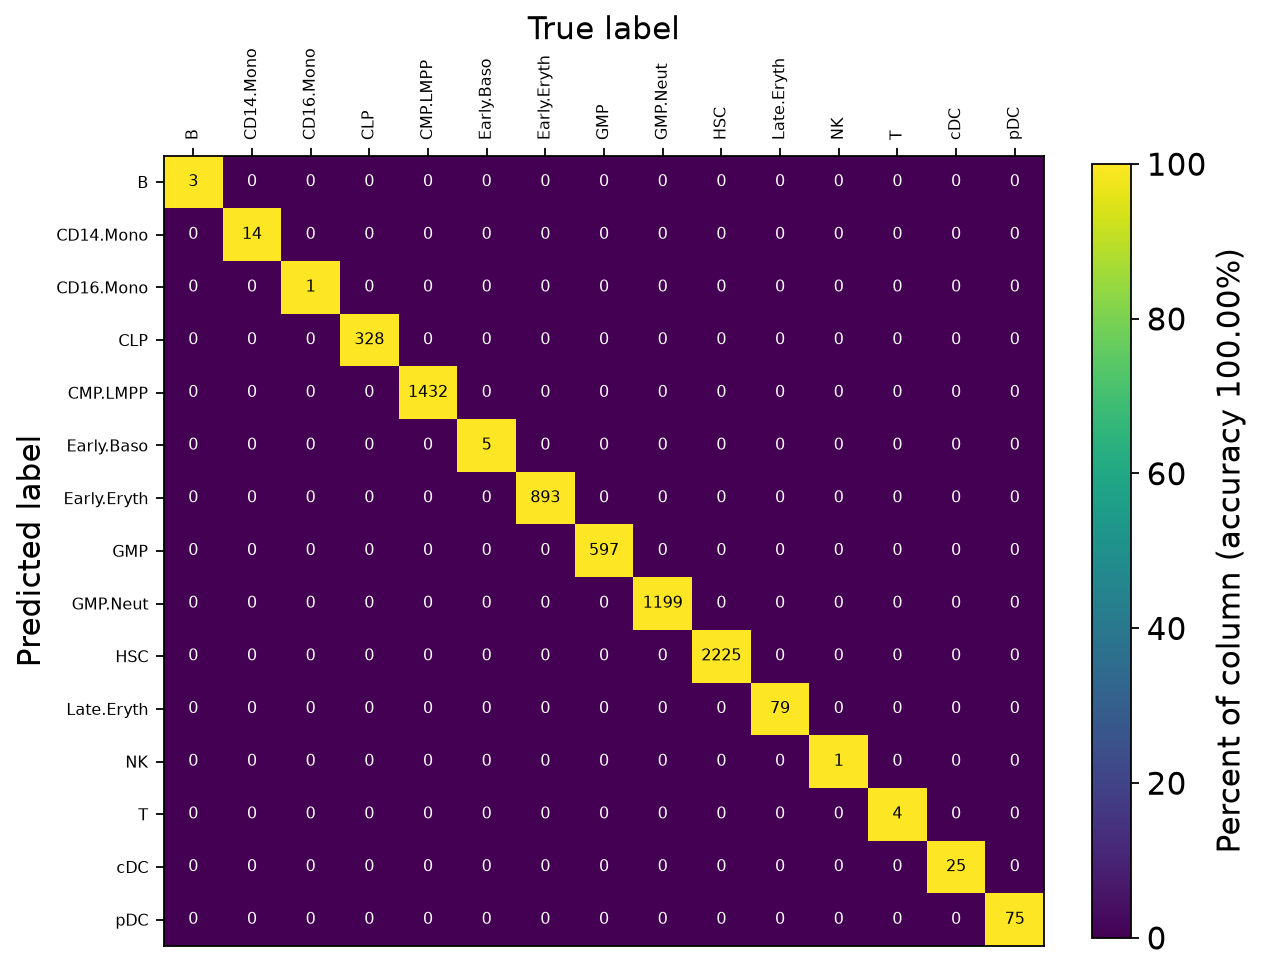

In [4]:
direct = query.obs["viewmastR_pred"].astype(str)
saved = inferred.obs["viewmastR_inferred"].astype(str)
prob_cols = [c for c in query.obs if c.startswith("prob_")]
diff = np.abs(query.obs[prob_cols].to_numpy() - inferred.obs[prob_cols].to_numpy())
print(f"label agreement: {(direct == saved).mean():.4f}")
print(f"largest probability difference: {diff.max():.2e}")
vm.confusion_matrix(saved, direct)
plt.show()

If any cells disagree, list them with their two competing probabilities. Such cells sit
on a boundary between two classes.

In [5]:
idx = np.flatnonzero(direct.to_numpy() != saved.to_numpy())
rows = [{"direct": direct.iat[i], "inferred": saved.iat[i],
         "p_direct": query.obs[f"prob_{direct.iat[i]}"].iat[i],
         "p_inferred": inferred.obs[f"prob_{saved.iat[i]}"].iat[i]} for i in idx]
print(pd.DataFrame(rows).to_string() if rows else "no disagreeing cells")

no disagreeing cells


## Versions

In [6]:
from importlib.metadata import version
for pkg in ("viewmastr", "scanpy", "anndata", "numpy", "scipy"):
    print(f"{pkg:10s} {version(pkg)}")

viewmastr  0.1.0
scanpy     1.12.5
anndata    0.13.4
numpy      2.5.4
scipy      1.18.1
